# Stimulus-level Analysis

## Purpose

This notebook configures and explores behavioral performance at the stimulus level across sessions and sensory modalities, focusing on individual visual, multimodal objects and auditory tone pulse frequencies.

## Available Functions

- **Multimodal object performance:** Analyze multimodal performance for individual objects across sessions using `plot_multimodal_performance_per_object` and summarize performance using `get_multimodal_performance_summary`.
- **Visual object performance:** Analyze visual performance for individual objects across sessions using `plot_visual_performance_per_object` and summarize performance using `get_visual_performance_summary`.
- **Auditory performance:** Analyze performance across tone pulse frequencies and sessions using `plot_auditory_performance_per_frequency` and `get_auditory_performance_summary`.


<div class="alert alert-info">
<strong>Note:</strong> Session IDs are stored in <code>config/beh_sessions.json</code>, organized by <code>animal_id</code> and <code>task_type</code> (e.g., <i>visual</i> , <i>audiovisual</i>).
</div>

In [1]:
from multimodal_analysis.db import get_schema_modules

exp, stim, beh, inter, rec, mice = get_schema_modules()

from multimodal_analysis.config import create_analysis_key, get_behavior_sessions
from multimodal_analysis.plots import (
    get_auditory_performance_summary,
    get_multimodal_performance_summary,
    get_visual_performance_summary,
    plot_auditory_performance_per_frequency,
    plot_multimodal_performance_per_object,
    plot_visual_performance_per_object,
)

Please enter DataJoint username:  eflab
Please enter DataJoint password:  ········


[2026-10-16 17:14:17,644][INFO]: Connecting eflab@database.eflab.org:3306
[2026-10-16 17:14:17,675][INFO]: Connected eflab@database.eflab.org:3306


In [2]:
# Define the animal and behavioral task for the analysis
# Set animal_id to None to include all animals
# Available task types: "visual", "audiovisual", "audiovisual_diff", "audiovisual_no_stim", 
# "audiovisual_obj215", "audiovisual_conflicted"
animal_id = 410
task_type = "audiovisual"

# Define the difficulty levels and sessions to exclude.
difficulties = [2]
excluded_sessions = []

In [3]:
# Get the behavioral sessions available for the selected animal and task.
sessions_idx = get_behavior_sessions(animal_id=animal_id, task_type=task_type)
print("sessions_idx: \n", sessions_idx)

# Define the first session to include in the analysis.
from_session = get_behavior_sessions(animal_id=animal_id, task_type=task_type)[0]
print("\nfrom_session:", from_session)

# Define the last session to include in the analysis.
to_session = get_behavior_sessions(animal_id=animal_id, task_type=task_type)[-1]
print("to_session:", to_session)

# Calculate the total number of sessions included in the analysis.
total_sessions = len(sessions_idx[:])
print("total_sessions:", total_sessions)

sessions_idx: 
 [135, 136, 137, 138, 139, 141, 144, 145, 146, 147, 148, 149, 151, 152, 154, 155, 156, 157, 158, 160, 161, 165, 167, 171, 173, 176, 178, 180, 181, 182, 184, 186, 189, 191, 194, 196]

from_session: 135
to_session: 196
total_sessions: 36


In [4]:
# Create the analysis configuration for the selected animal and sessions.
# Parameters:
# animal_id (int): Animal ID.
# from_session (int): First session.
# to_session (int): Last session.
# difficulties (list): Difficulty levels to include.
# excluded_sessions (list): Sessions to exclude.
key = create_analysis_key(
    animal_id, from_session, to_session, difficulties, excluded_sessions
)
print(key)

{'animal_id': 410, 'sessions': (135, 196), 'difficulties': [2], 'excluded_sessions': []}


In [5]:
# Create a DataFrame summarizing multimodal performance for each object across sessions.
# Includes: session_trials, obj_perf (performance), obj_rew (rewarded trials)
# obj_pun (punished trials), valid_obj_trials, obj_abrt (aborted trials), obj_pct (object percentage)
# Parameters:
# key (dict), stim (Stimulus schema), exp (Experiment schema)
multi_perf_df = get_multimodal_performance_summary(key,stim,exp)

Object 212:


,animal_id,session,date,session_trials,obj_perf,obj_rew,obj_pun,valid_obj_trials,obj_abrt,obj_pct
0,410,135,2026-06-12,775,0.80,28,7,35,57,4.52
1,410,136,2026-06-13,766,0.81,26,6,32,54,4.18
2,410,137,2026-06-14,683,0.73,22,8,30,54,4.39
3,410,138,2026-06-15,796,0.72,26,10,36,75,4.52
4,410,139,2026-06-16,631,0.76,22,7,29,36,4.60
5,410,141,2026-06-17,500,0.60,27,18,45,26,9.00
6,410,144,2026-06-19,706,0.60,27,18,45,58,6.37
7,410,145,2026-06-20,679,0.62,26,16,42,51,6.19
8,410,146,2026-06-20,454,0.57,25,19,44,18,9.69
9,410,147,2026-06-21,475,0.69,33,15,48,21,10.11


Object 213:


,animal_id,session,date,session_trials,obj_perf,obj_rew,obj_pun,valid_obj_trials,obj_abrt,obj_pct
0,410,135,2026-06-12,775,0.76,26,8,34,72,4.39
1,410,136,2026-06-13,766,0.73,24,9,33,52,4.31
2,410,137,2026-06-14,683,0.84,27,5,32,55,4.69
3,410,138,2026-06-15,796,0.78,31,9,40,61,5.03
4,410,139,2026-06-16,631,0.90,26,3,29,33,4.60
5,410,141,2026-06-17,500,0.59,35,24,59,22,11.80
6,410,144,2026-06-19,706,0.63,34,20,54,50,7.65
7,410,145,2026-06-20,679,0.86,38,6,44,50,6.48
8,410,146,2026-06-20,454,0.63,29,17,46,17,10.13
9,410,147,2026-06-21,475,0.63,41,24,65,29,13.68


Object 218:


,animal_id,session,date,session_trials,obj_perf,obj_rew,obj_pun,valid_obj_trials,obj_abrt,obj_pct
0,410,135,2026-06-12,775,0.51,22,21,43,93,5.55
1,410,136,2026-06-13,766,0.46,26,30,56,94,7.31
2,410,137,2026-06-14,683,0.63,27,16,43,78,6.30
3,410,138,2026-06-15,796,0.48,30,32,62,84,7.79
4,410,139,2026-06-16,631,0.43,25,33,58,70,9.19
5,410,141,2026-06-17,500,0.70,32,14,46,31,9.20
6,410,144,2026-06-19,706,0.73,33,12,45,69,6.37
7,410,145,2026-06-20,679,0.72,31,12,43,62,6.33
8,410,146,2026-06-20,454,0.63,26,15,41,27,9.03
9,410,147,2026-06-21,475,0.66,25,13,38,19,8.00


Object 219:


,animal_id,session,date,session_trials,obj_perf,obj_rew,obj_pun,valid_obj_trials,obj_abrt,obj_pct
0,410,135,2026-06-12,775,0.72,38,15,53,69,6.84
1,410,136,2026-06-13,766,0.53,31,27,58,103,7.57
2,410,137,2026-06-14,683,0.66,21,11,32,81,4.69
3,410,138,2026-06-15,796,0.70,40,17,57,85,7.16
4,410,139,2026-06-16,631,0.48,29,31,60,60,9.51
5,410,141,2026-06-17,500,0.76,29,9,38,23,7.60
6,410,144,2026-06-19,706,0.78,35,10,45,53,6.37
7,410,145,2026-06-20,679,0.67,33,16,49,70,7.22
8,410,146,2026-06-20,454,0.65,31,17,48,17,10.57
9,410,147,2026-06-21,475,0.76,34,11,45,12,9.47


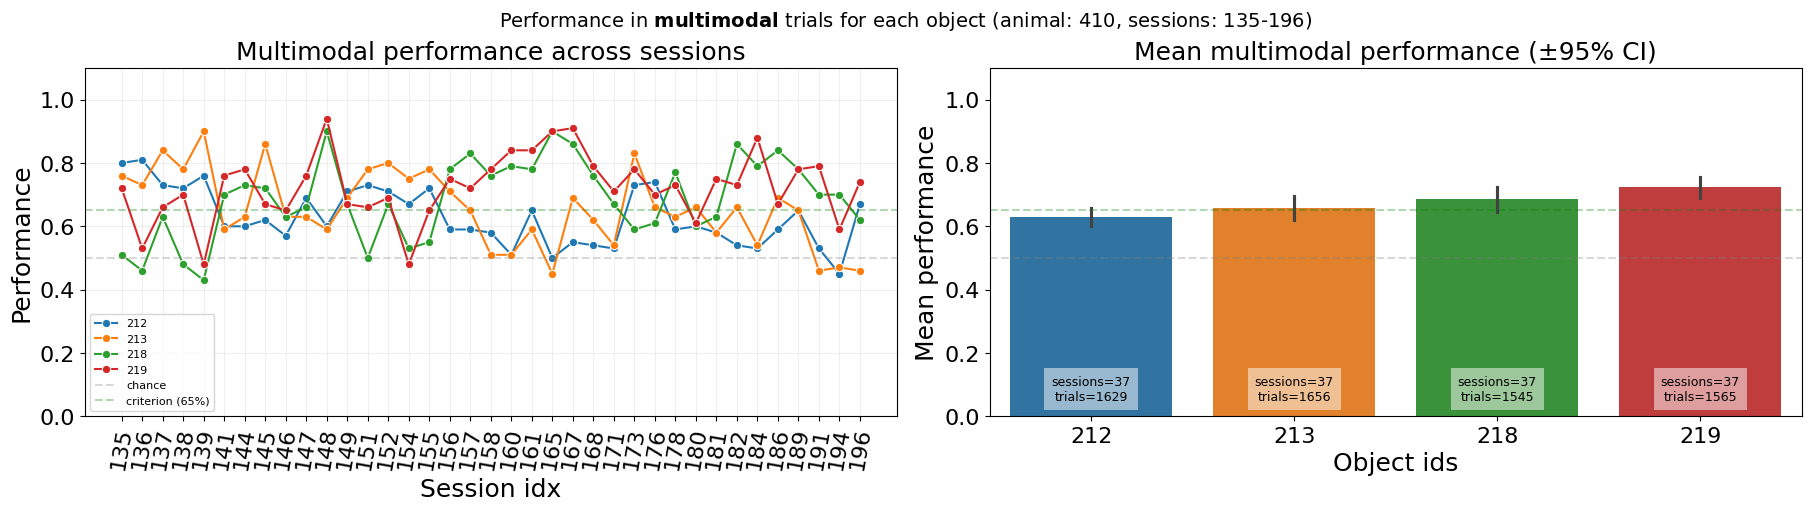

In [6]:
# Plot multimodal performance across sessions and mean performance per object, with 95% confidence intervals.
# Parameters:
# key (dict), stim (stimulus schema), exp (experiment schema), criterion (float)
multi_perf_plot = plot_multimodal_performance_per_object(key,stim,exp,criterion=0.65)

In [7]:
# Create a DataFrame summarizing visual performance for each object across sessions.
# Includes: session_trials, obj_perf, obj_rew (rewarded trials)
# obj_pun (punished trials), valid_obj_trials, obj_abrt (aborted trials), obj_pct (object percentage)
# Parameters:
# key (dict), stim (Stimulus schema), exp (Experiment schema)
visual_perf_df = get_visual_performance_summary(key,stim,exp)

Object 212:


,animal_id,session,date,session_trials,obj_perf,obj_rew,obj_pun,valid_obj_trials,obj_abrt,obj_pct
0,410,135,2026-06-12,775,0.53,9,8,17,23,2.19
1,410,136,2026-06-13,766,0.62,8,5,13,12,1.70
2,410,137,2026-06-14,683,0.43,6,8,14,16,2.05
3,410,138,2026-06-15,796,0.73,8,3,11,9,1.38
4,410,139,2026-06-16,631,0.71,12,5,17,8,2.69
5,410,141,2026-06-17,500,0.61,14,9,23,3,4.60
6,410,144,2026-06-19,706,0.45,9,11,20,17,2.83
7,410,145,2026-06-20,679,0.47,7,8,15,17,2.21
8,410,146,2026-06-20,454,0.62,8,5,13,7,2.86
9,410,147,2026-06-21,475,0.27,4,11,15,10,3.16


Object 213:


,animal_id,session,date,session_trials,obj_perf,obj_rew,obj_pun,valid_obj_trials,obj_abrt,obj_pct
0,410,135,2026-06-12,775,0.88,15,2,17,23,2.19
1,410,136,2026-06-13,766,1.00,9,0,9,9,1.17
2,410,137,2026-06-14,683,0.67,8,4,12,25,1.76
3,410,138,2026-06-15,796,0.68,15,7,22,19,2.76
4,410,139,2026-06-16,631,0.85,11,2,13,6,2.06
5,410,141,2026-06-17,500,0.44,8,10,18,10,3.60
6,410,144,2026-06-19,706,0.40,6,9,15,19,2.12
7,410,145,2026-06-20,679,0.72,13,5,18,14,2.65
8,410,146,2026-06-20,454,0.50,9,9,18,8,3.96
9,410,147,2026-06-21,475,0.35,8,15,23,8,4.84


Object 218:


,animal_id,session,date,session_trials,obj_perf,obj_rew,obj_pun,valid_obj_trials,obj_abrt,obj_pct
0,410,135,2026-06-12,775,0.59,13,9,22,24,2.84
1,410,136,2026-06-13,766,0.36,9,16,25,28,3.26
2,410,137,2026-06-14,683,0.62,10,6,16,18,2.34
3,410,138,2026-06-15,796,0.65,13,7,20,31,2.51
4,410,139,2026-06-16,631,0.62,16,10,26,17,4.12
5,410,141,2026-06-17,500,0.80,16,4,20,4,4.00
6,410,144,2026-06-19,706,0.62,10,6,16,20,2.27
7,410,145,2026-06-20,679,0.77,17,5,22,18,3.24
8,410,146,2026-06-20,454,0.74,17,6,23,7,5.07
9,410,147,2026-06-21,475,0.61,11,7,18,5,3.79


Object 219:


,animal_id,session,date,session_trials,obj_perf,obj_rew,obj_pun,valid_obj_trials,obj_abrt,obj_pct
0,410,135,2026-06-12,775,0.58,11,8,19,20,2.45
1,410,136,2026-06-13,766,0.69,11,5,16,26,2.09
2,410,137,2026-06-14,683,0.76,16,5,21,26,3.07
3,410,138,2026-06-15,796,0.70,16,7,23,18,2.89
4,410,139,2026-06-16,631,0.50,10,10,20,18,3.17
5,410,141,2026-06-17,500,0.88,15,2,17,8,3.40
6,410,144,2026-06-19,706,0.85,11,2,13,16,1.84
7,410,145,2026-06-20,679,0.82,9,2,11,21,1.62
8,410,146,2026-06-20,454,0.75,12,4,16,5,3.52
9,410,147,2026-06-21,475,0.76,13,4,17,7,3.58


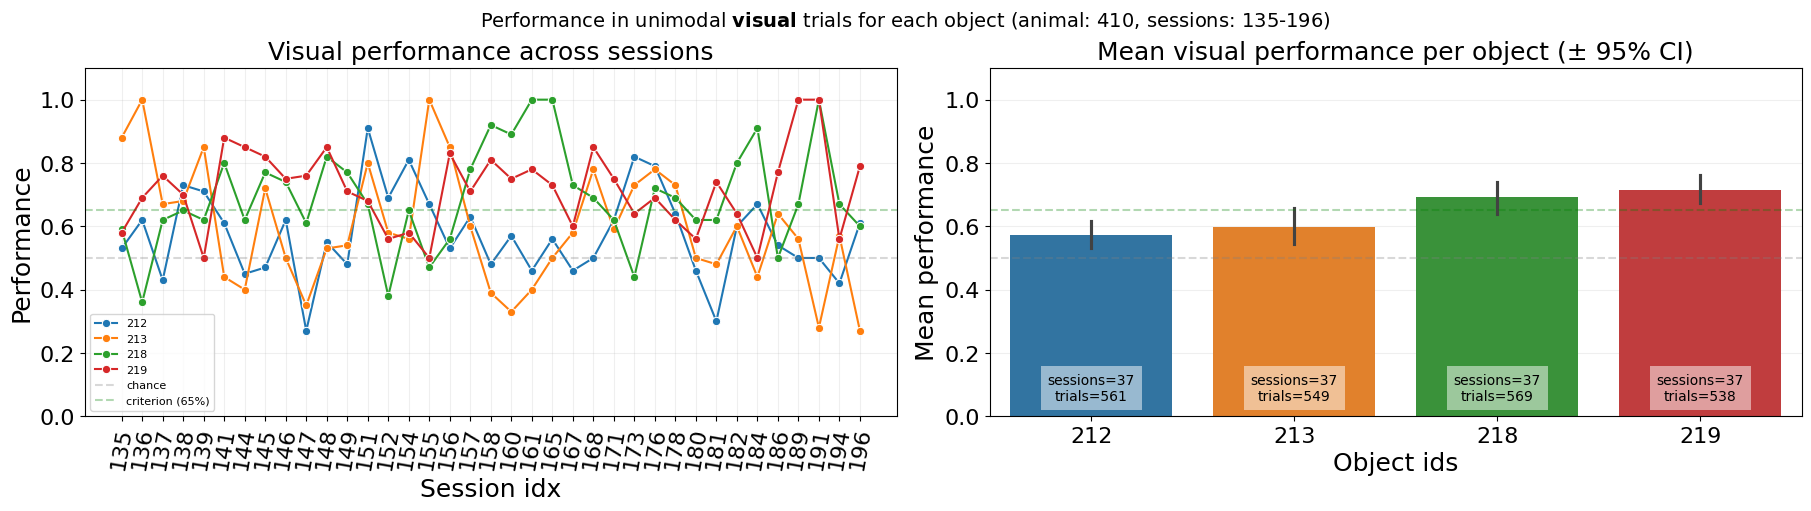

In [8]:
# Plot visual performance across sessions and mean performance per object, with 95% confidence intervals.
# Parameters:
# key (dict), stim (stimulus schema), exp (experiment schema), criterion (float)
visual_perf_plot = plot_visual_performance_per_object(key,stim,exp,criterion=0.65)

In [9]:
# Create a DataFrame summarizing auditory performance for each tone pulse frequency across sessions.
# Includes: performance, rewarded, punished, and aborted trials; valid trials; and tone pulse frequency.
# Parameters:
# key (dict), stim (Stimulus schema), exp (Experiment schema), 
# pulse_freq (str or int): "all", 100, or 0
aud_perf_df = get_auditory_performance_summary(key, stim, exp, pulse_freq="all")

,animal_id,session,date,performance,reward,punish,valid_trials,abort,n_trials,tone_pulse_freq
0,410,135,2026-06-12,1.00,8,0,8,53,61,100
1,410,136,2026-06-13,1.00,10,0,10,52,62,100
2,410,137,2026-06-14,1.00,12,0,12,51,63,100
3,410,138,2026-06-15,0.94,16,1,17,29,46,100
4,410,139,2026-06-16,0.90,9,1,10,27,37,100
5,410,141,2026-06-17,0.64,16,9,25,32,57,100
6,410,144,2026-06-19,0.73,24,9,33,40,73,100
7,410,145,2026-06-20,0.77,17,5,22,31,53,100
8,410,146,2026-06-20,0.68,23,11,34,14,48,100
9,410,147,2026-06-21,0.40,17,25,42,14,56,100


,animal_id,session,date,performance,reward,punish,valid_trials,abort,n_trials,tone_pulse_freq
0,410,135,2026-06-12,0.00,0,9,9,83,92,0
1,410,136,2026-06-13,0.15,2,11,13,70,83,0
2,410,137,2026-06-14,0.06,1,17,18,48,66,0
3,410,138,2026-06-15,0.00,0,26,26,70,96,0
4,410,139,2026-06-16,0.08,2,24,26,67,93,0
5,410,141,2026-06-17,0.29,8,20,28,22,50,0
6,410,144,2026-06-19,0.30,11,26,37,41,78,0
7,410,145,2026-06-20,0.25,9,27,36,43,79,0
8,410,146,2026-06-20,0.45,20,24,44,7,51,0
9,410,147,2026-06-21,0.61,14,9,23,16,39,0


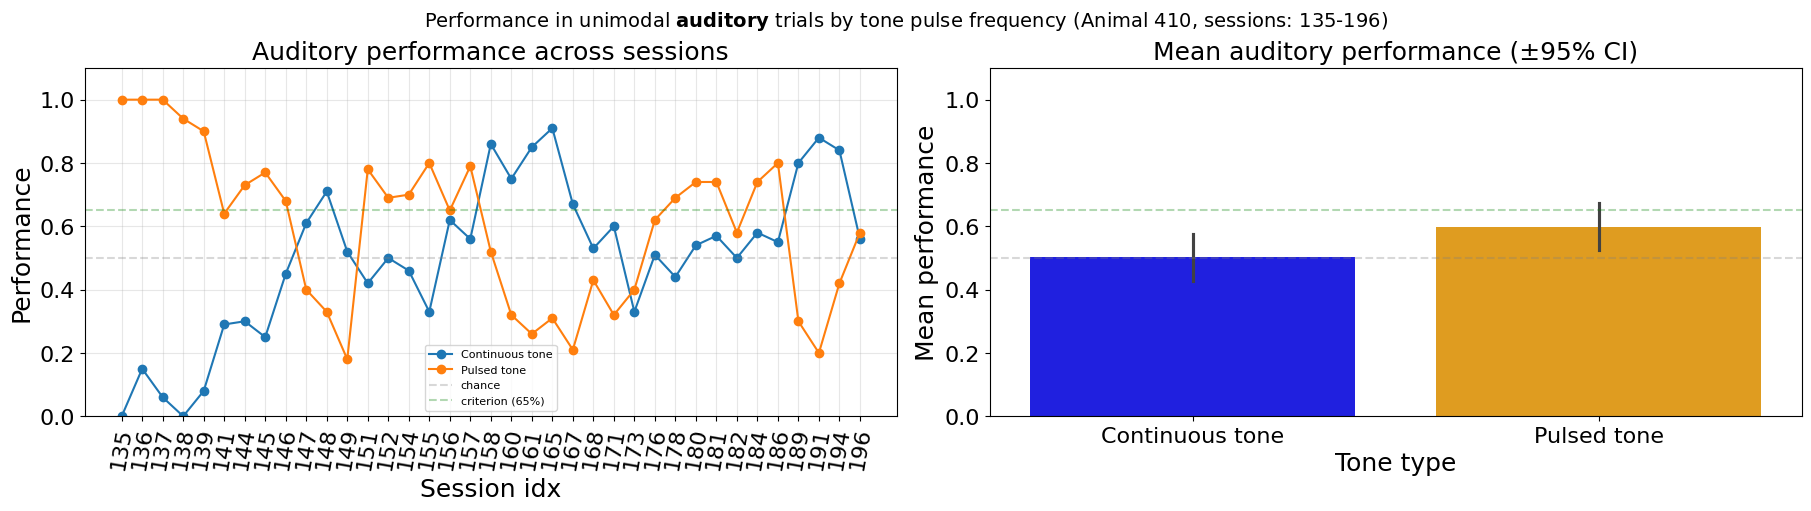

In [10]:
# Plot auditory performance across sessions and mean performance per tone pulse frequency, with 95% confidence intervals.
# Parameters:
# key (dict), stim (stimulus schema), exp (experiment schema), criterion (float)
plot_auditory_performance_per_frequency(key, stim, exp, criterion=0.65)